# A01-GN 





In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "A01-GN"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,A01-GN
Mô hình,GNNClustering
Khách,4327
Số chiều đầu vào,3
Biến đổi,none
Scaler,StandardScaler
PCA,0.9


{
  "configuration": "A01",
  "transform": "none",
  "scaler": "StandardScaler",
  "pca_requested": 0.9,
  "model_input_dimensions": 3,
  "pca_explained_variance_ratio": [
    0.5638240337173058,
    0.30163072566982435,
    0.13454524061286977
  ],
  "pca_explained_variance_total": 1.0,
  "pca_components": [
    [
      -0.37402340703988635,
      0.6748844371544975,
      0.6361112225648374
    ],
    [
      0.9112201331059055,
      0.13978679633999763,
      0.3874758322675827
    ],
    [
      0.17258145905262023,
      0.7245623838260283,
      -0.6672518204813022
    ]
  ]
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
k,6
n_clusters,6
noise_pct,0.0
smallest_cluster,475
largest_cluster_pct_all,22.140051
silhouette,0.383806
dbi,1.010149
chi,1476.8096
inertia,3969.814353
eligible,True


,k,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,inertia,eligible
0,2,2,0.0,1435,66.836145,0.244512,1.782153,988.045516,8753.902509,True
1,3,3,0.0,1361,36.861567,0.290814,1.485146,1112.838459,7099.457696,True
2,4,4,0.0,912,29.211925,0.325646,1.265300,1234.866394,5791.074727,True
3,5,5,0.0,480,26.623527,0.353063,1.100772,1341.362218,4797.723108,True
4,6,6,0.0,475,22.140051,0.383806,1.010149,1476.809600,3969.814353,True
5,7,7,0.0,33,22.140051,0.396089,0.869426,1704.441949,3193.594980,False
6,8,8,0.0,34,19.228103,0.388819,0.901683,1700.901796,2862.533527,False
7,9,9,0.0,33,15.853940,0.384369,0.888019,1735.196232,2551.412299,False
8,10,10,0.0,29,15.784608,0.386471,0.887104,1740.882397,2322.941624,False


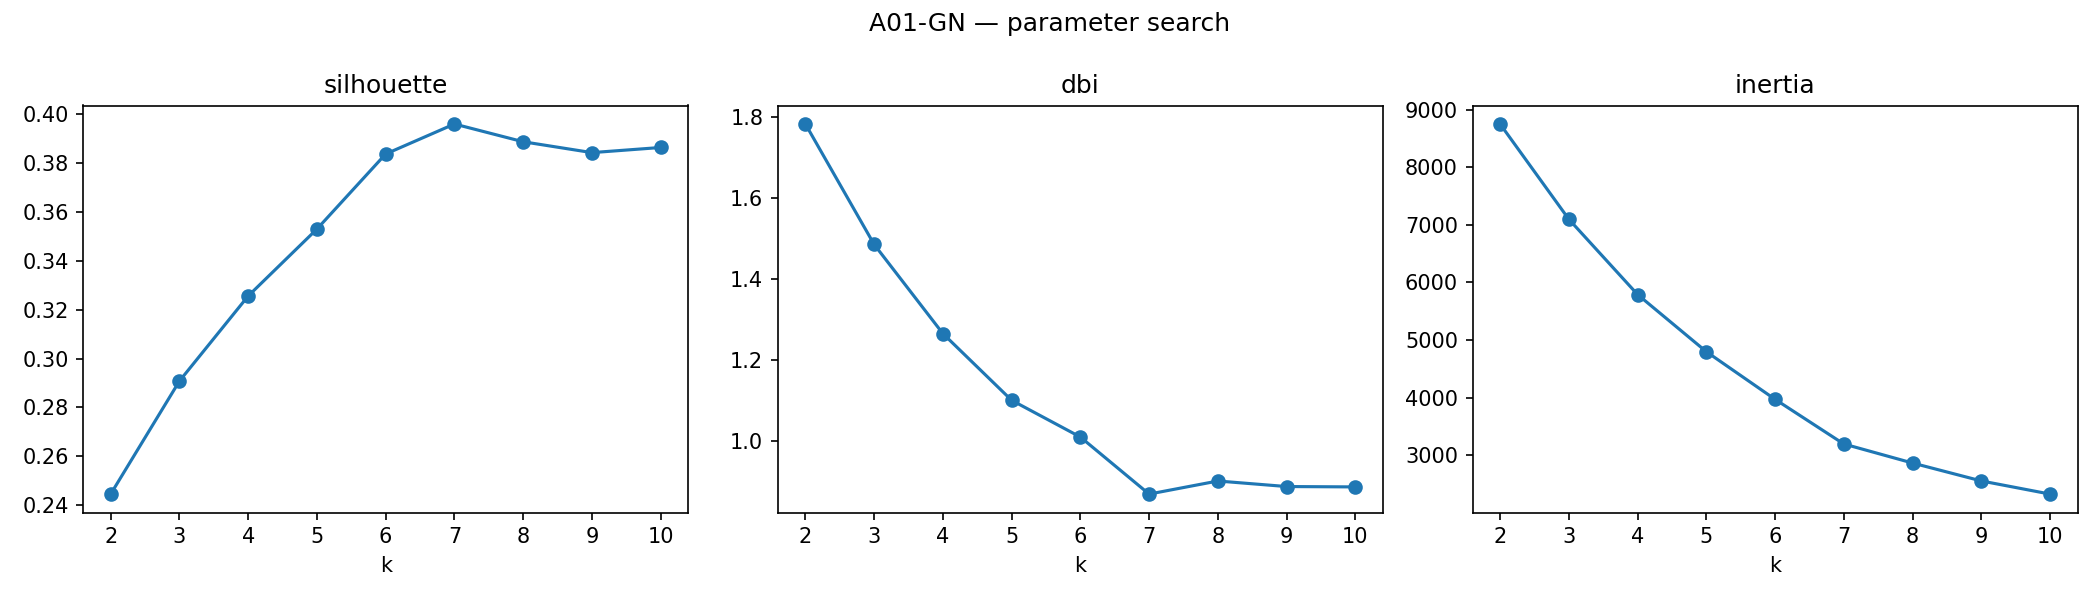

{
  "architecture": "GCN(input,32)-ReLU-GCN(32,8); inner-product edge decoder",
  "graph": "symmetrized union 15-nearest-neighbor Euclidean graph from PCA/model input",
  "message_passing": "D^-1/2 (A_train + I) D^-1/2; validation/test positives removed",
  "train_positive_edges": 32096,
  "validation_positive_edges": 4011,
  "test_positive_edges": 4011,
  "epochs_run": 200,
  "best_epoch": 198,
  "initial_validation_bce": 0.6883407831192017,
  "best_validation_bce": 0.4687439203262329,
  "initial_validation_diagnostic": {
    "roc_auc": 0.601007600576848,
    "average_precision": 0.6243942937616715
  },
  "validation_link_metrics": {
    "roc_auc": 0.9486231176406492,
    "average_precision": 0.9257535135510753
  },
  "test_link_metrics": {
    "roc_auc": 0.9501497098387065,
    "average_precision": 0.9273072686912212
  },
  "test_usage": "evaluated once after validation checkpoint selection; never used for training or cluster-k selection",
  "negative_sampling": "1:1 uniform non-edge

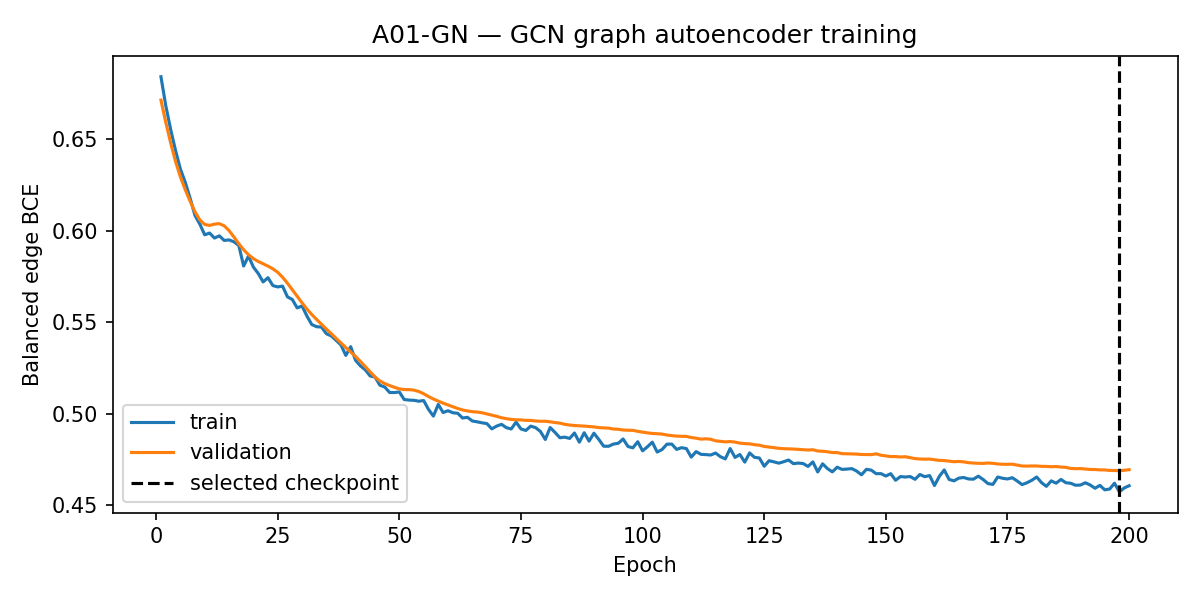

,epoch,train_link_bce,validation_link_bce
0,1,0.684199,0.671427
1,2,0.668287,0.659227
2,3,0.655315,0.647966
3,4,0.643867,0.637846
4,5,0.633716,0.629407
...,...,...,...
195,196,0.458766,0.468937
196,197,0.461946,0.468920
197,198,0.457248,0.468744
198,199,0.459370,0.469043


In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,1
2,12349,19,1,1457.55,3
3,12350,311,1,294.40,4
4,12352,37,7,1385.74,1
5,12353,205,1,89.00,2
6,12354,233,1,1079.40,2
7,12355,215,1,459.40,2
8,12356,23,3,2487.43,3
9,12357,34,1,6207.67,1


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,0,655,9.0,10.0,3543.260,5159215.330,15.137509,61.304005
1,1,732,53.0,4.0,1485.365,1496900.281,16.917033,17.786810
2,2,784,177.0,1.0,356.840,426761.111,18.118789,5.070958
3,3,958,16.0,2.0,632.025,785101.920,22.140051,9.328917
4,4,475,309.0,1.0,268.580,182065.510,10.977583,2.163380
5,5,723,64.0,1.0,371.010,365744.221,16.709036,4.345929


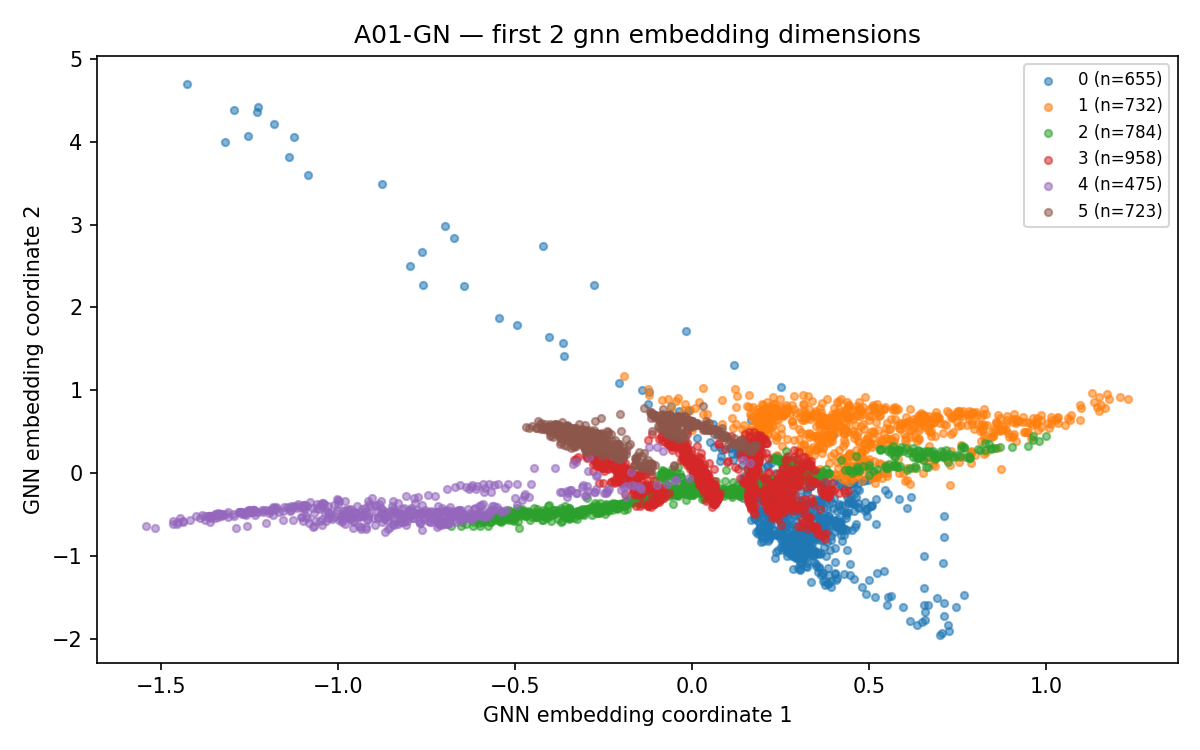

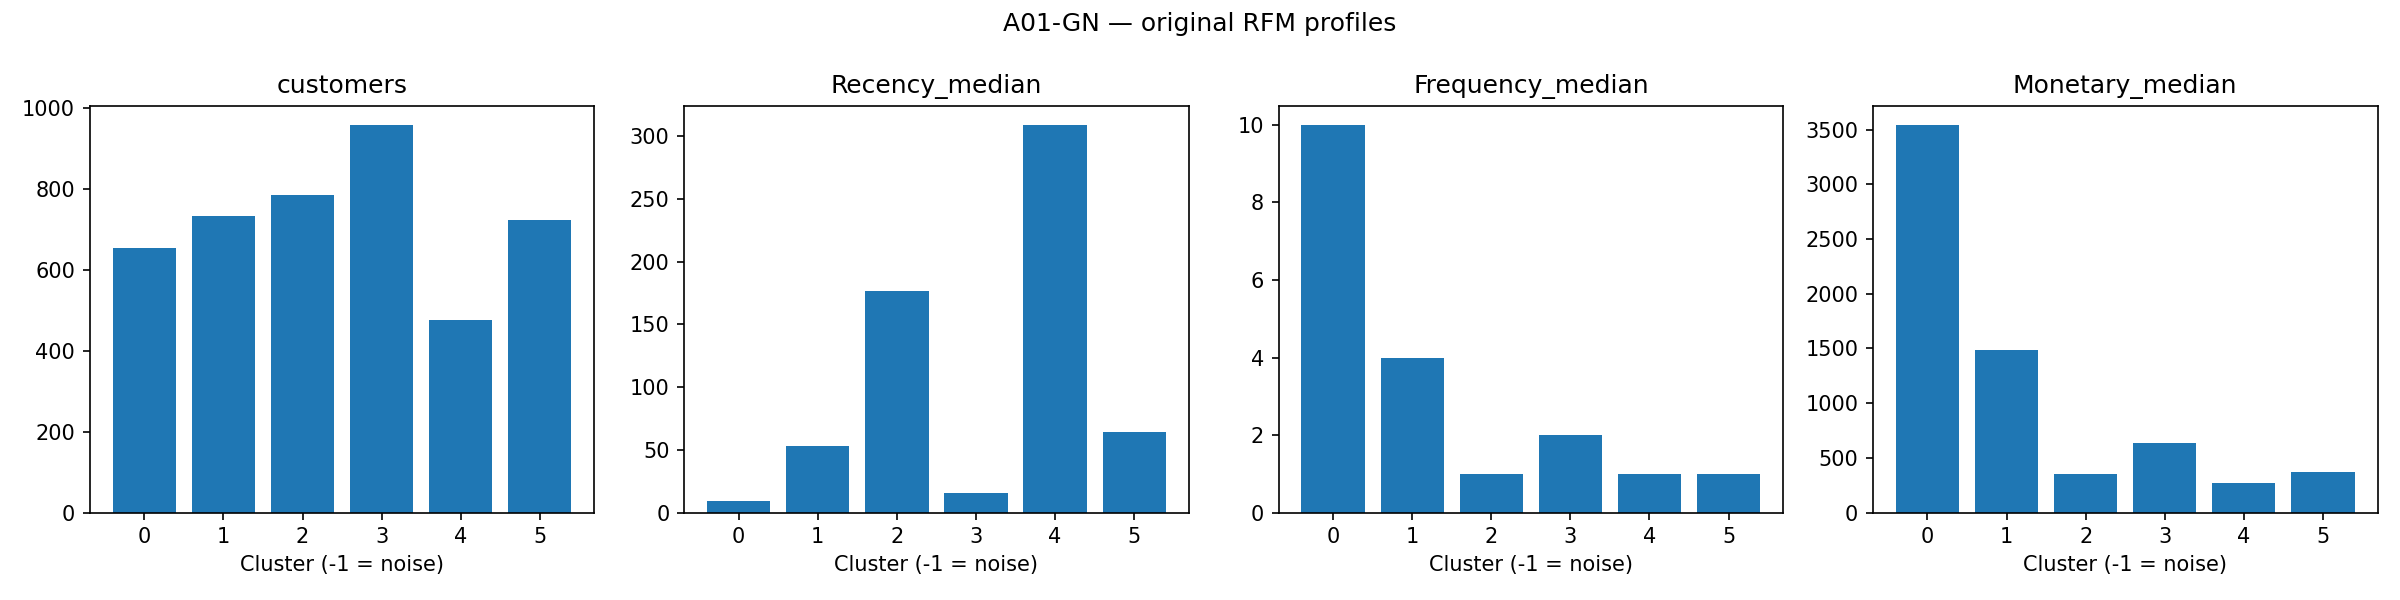

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:


,Giá trị
n_clusters,6.000000
noise_pct,0.000000
smallest_cluster,475.000000
largest_cluster_pct_all,22.140051
silhouette,0.266635
dbi,1.016765
chi,703.563940


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.
- Transductive GNN: graph/embeddings apply to the fitted customers and their original order; unseen nodes require graph reconstruction and retraining.
- Held-out link prediction evaluates reconstruction of an RFM-derived graph, not business outcomes, customer value prediction, or segmentation ground truth.
- Only one fixed random seed and one GNN architecture are evaluated; graph and architecture choices are explicit implementation assumptions.